<a href="https://colab.research.google.com/github/GuiGodoy21/Aulas/blob/main/Usando_matplotlib.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== DataFrame Inicial ===
   Mes  Notebook  Mouse  Teclado
0  Jan        20     50       30
1  Fev        25     55       28
2  Mar        22     48       35
3  Abr        30     60       40
4  Mai        35     65       38
5  Jun        40     70       45


1. EXPLORAÇÃO DOS DADOS

--- Primeiras Linhas (head) ---
   Mes  Notebook  Mouse  Teclado
0  Jan        20     50       30
1  Fev        25     55       28
2  Mar        22     48       35
3  Abr        30     60       40
4  Mai        35     65       38

--- Dimensões do DataFrame (Linhas, Colunas) ---
(6, 4)

--- Estatísticas Descritivas ---
        Notebook      Mouse    Teclado
count   6.000000   6.000000   6.000000
mean   28.666667  58.000000  36.000000
std     7.788881   8.602325   6.356099
min    20.000000  48.000000  28.000000
25%    22.750000  51.250000  31.250000
50%    27.500000  57.500000  36.500000
75%    33.750000  63.750000  39.500000
max    40.000000  70.000000  45.000000


2. INDICADORES (NumPy)
[Notebook] -> Média

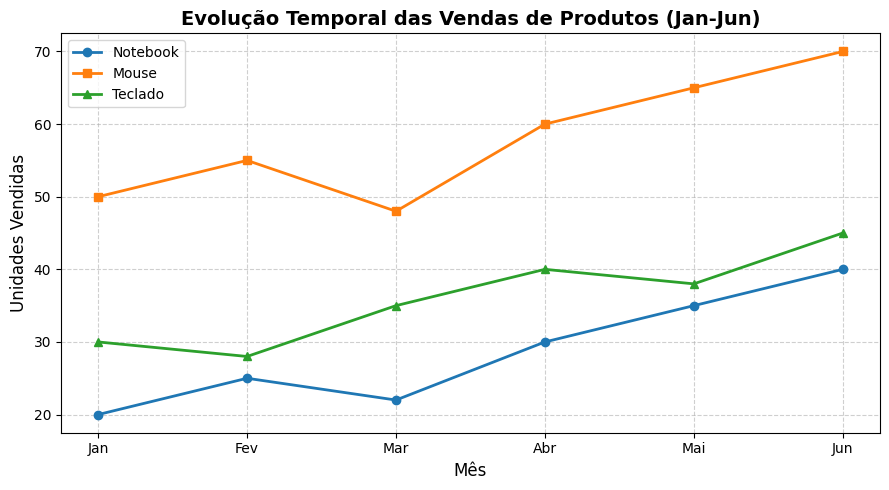

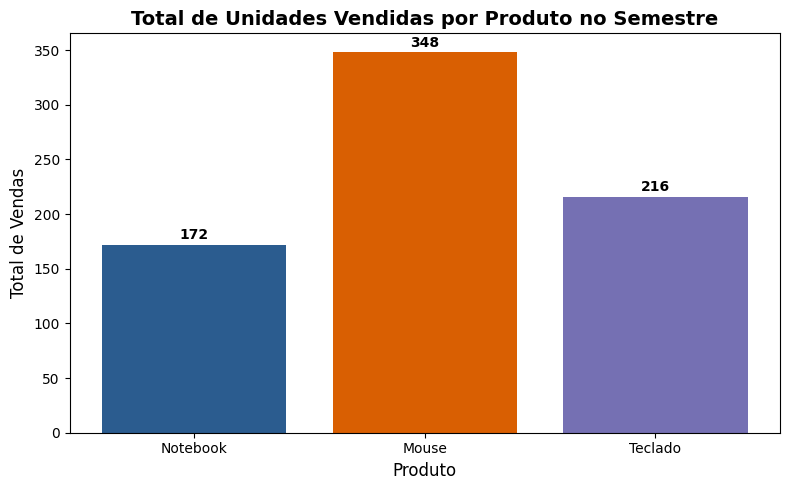

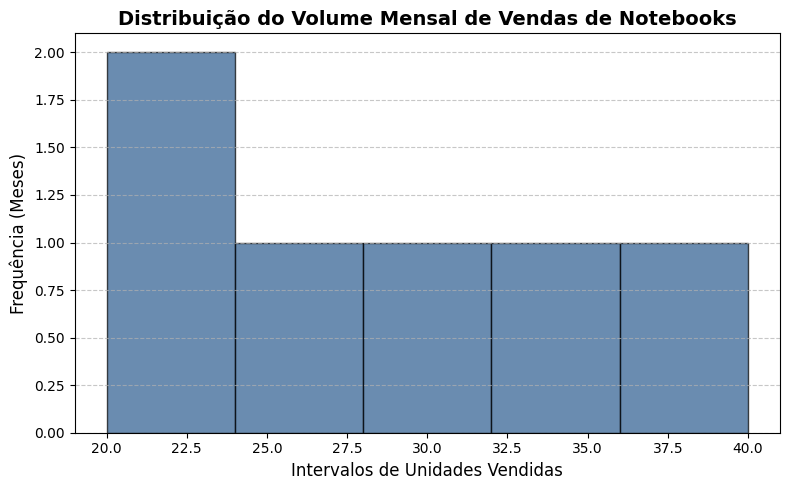

6. INTERPRETAÇÃO E CONCLUSÕES
- Produto com maior volume total: Mouse (348 unidades no total).
- Mês de maior venda de Notebook: Jun (40 unidades).
- Mês de maior venda de Mouse: Jun (70 unidades).
- Mês de maior venda de Teclado: Jun (45 unidades).

Conclusão baseada nos gráficos:
Observa-se uma tendência clara e consistente de crescimento das vendas a partir de Março/Abril 
para todos os três produtos, culminando no pico de vendas no mês de Junho. 
O Mouse é o produto de maior volume de vendas em todo o período, mantendo liderança constante.




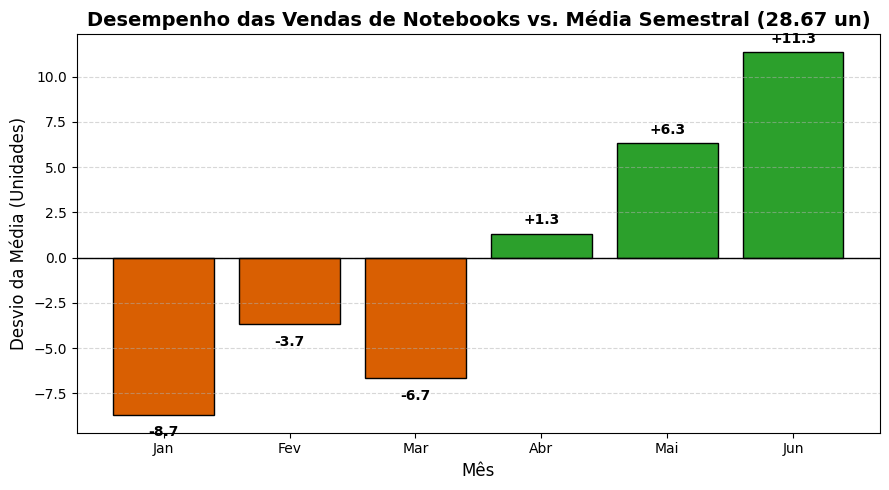

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dados = {
    "Mes": ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun"],
    "Notebook": [20, 25, 22, 30, 35, 40],
    "Mouse": [50, 55, 48, 60, 65, 70],
    "Teclado": [30, 28, 35, 40, 38, 45]
}

df = pd.DataFrame(dados)
print("=== DataFrame Inicial ===")
print(df)
print("\n" + "="*50 + "\n")

print("1. EXPLORAÇÃO DOS DADOS")
print("\n--- Primeiras Linhas (head) ---")
print(df.head())

print("\n--- Dimensões do DataFrame (Linhas, Colunas) ---")
print(df.shape)

print("\n--- Estatísticas Descritivas ---")
print(df.describe())
print("\n" + "="*50 + "\n")

print("2. INDICADORES (NumPy)")
produtos = ["Notebook", "Mouse", "Teclado"]

for produto in produtos:
    vendas = df[produto].to_numpy()
    media = np.mean(vendas)
    maximo = np.max(vendas)
    minimo = np.min(vendas)
    print(f"[{produto}] -> Média: {media:.2f} | Maior Valor: {maximo} | Menor Valor: {minimo}")

print("\n" + "="*50 + "\n")

plt.figure(figsize=(9, 5))
plt.plot(df["Mes"], df["Notebook"], marker='o', label="Notebook", linewidth=2)
plt.plot(df["Mes"], df["Mouse"], marker='s', label="Mouse", linewidth=2)
plt.plot(df["Mes"], df["Teclado"], marker='^', label="Teclado", linewidth=2)

plt.title("Evolução Temporal das Vendas de Produtos (Jan-Jun)", fontsize=14, fontweight='bold')
plt.xlabel("Mês", fontsize=12)
plt.ylabel("Unidades Vendidas", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

totais_produtos = {p: np.sum(df[p].to_numpy()) for p in produtos}

plt.figure(figsize=(8, 5))
plt.bar(totais_produtos.keys(), totais_produtos.values(), color=['#2b5c8f', '#d95f02', '#7570b3'])

plt.title("Total de Unidades Vendidas por Produto no Semestre", fontsize=14, fontweight='bold')
plt.xlabel("Produto", fontsize=12)
plt.ylabel("Total de Vendas", fontsize=12)
for i, (prod, valor) in enumerate(totais_produtos.items()):
    plt.text(i, valor + 5, str(valor), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(df["Notebook"], bins=5, color='#2b5c8f', edgecolor='black', alpha=0.7)

plt.title("Distribuição do Volume Mensal de Vendas de Notebooks", fontsize=14, fontweight='bold')
plt.xlabel("Intervalos de Unidades Vendidas", fontsize=12)
plt.ylabel("Frequência (Meses)", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

total_mouse = totais_produtos["Mouse"]
total_notebook = totais_produtos["Notebook"]
total_teclado = totais_produtos["Teclado"]

mes_max_notebook = df.loc[df["Notebook"].idxmax(), "Mes"]
mes_max_mouse = df.loc[df["Mouse"].idxmax(), "Mes"]
mes_max_teclado = df.loc[df["Teclado"].idxmax(), "Mes"]

print("6. INTERPRETAÇÃO E CONCLUSÕES")
print(f"- Produto com maior volume total: Mouse ({total_mouse} unidades no total).")
print(f"- Mês de maior venda de Notebook: {mes_max_notebook} ({df['Notebook'].max()} unidades).")
print(f"- Mês de maior venda de Mouse: {mes_max_mouse} ({df['Mouse'].max()} unidades).")
print(f"- Mês de maior venda de Teclado: {mes_max_teclado} ({df['Teclado'].max()} unidades).")

print("\nConclusão baseada nos gráficos:")
print("Observa-se uma tendência clara e consistente de crescimento das vendas a partir de Março/Abril ")
print("para todos os três produtos, culminando no pico de vendas no mês de Junho. ")
print("O Mouse é o produto de maior volume de vendas em todo o período, mantendo liderança constante.")

print("\n" + "="*50 + "\n")

media_notebook = np.mean(df["Notebook"].to_numpy())
df["Diferenca_Media"] = df["Notebook"] - media_notebook

cores = ['#d95f02' if x < 0 else '#2ca02c' for x in df["Diferenca_Media"]]

plt.figure(figsize=(9, 5))
plt.bar(df["Mes"], df["Diferenca_Media"], color=cores, edgecolor='black')
plt.axhline(0, color='black', linewidth=1)

plt.title("Desempenho das Vendas de Notebooks vs. Média Semestral (28.67 un)", fontsize=14, fontweight='bold')
plt.xlabel("Mês", fontsize=12)
plt.ylabel("Desvio da Média (Unidades)", fontsize=12)

for i, val in enumerate(df["Diferenca_Media"]):
    pos_y = val + 0.5 if val >= 0 else val - 1.2
    plt.text(i, pos_y, f"{val:+.1f}", ha='center', fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()